<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# **Procesamiento de Lenguaje Natural**
## **Desafio, Traductor**

**Este desafío puede realizarse de manera individual o en pareja. En caso de realizarlo en pareja, solo uno de los integrantes deberá subir el desafío.**


Nombre(s):
* Luis Jose Paredes Ramirez

### **Consigna**

* Replicar el modelo traductor desarrollado en clase (https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/blob/set_2026/Clase%206/C%C3%B3digo/Traductor.ipynb) y extender su entrenamiento utilizando un conjunto de datos más amplio y secuencias de mayor longitud.
* Modificar valores de hiperparámetros (por ejemplo, el número de unidades en las capas LSTM) y analizar su impacto en el desempeño del traductor.
* Analizar el impacto del número de neuronas en las capas recurrentes, comparando el desempeño de distintas configuraciones del modelo.
* Generar y presentar al menos cinco ejemplos de traducciones producidas por el modelo entrenado.
* Interpretar a detalle los resultados obtenidos, considerando métricas de evaluación, calidad de las traducciones y posibles limitaciones del enfoque utilizado.
 
### **Actividades opcionales**

* Incorporar embeddings preentrenados para ambos idiomas y evaluar su efecto sobre el rendimiento del modelo.
* Experimentar con diferentes estrategias de generación de secuencias, como muestreo aleatorio (sampling) o búsqueda por haz (beam search).
* Implementar y entrenar una versión equivalente del modelo utilizando PyTorch, comparando los resultados con la implementación original.

---

In [19]:
import os
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer, text_to_word_sequence
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.layers import Input, LSTM, Dense, Embedding, Dropout
from tensorflow.keras.models import Model
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

In [ ]:
"""
Nota sobre tiempos: en CPU (sin GPU) el entrenamiento completo tardó ~2 h 55 min
El costo lo domina la capa softmax sobre el vocabulario en cada paso de tiempo. 
Si se necesita acortar, se puede reducir `EXT_NUM_SENTENCES`, quitar `512` de `UNITS_LIST`, o correr el notebook en Colab con GPU.
"""

SEED = 40

# Experimento A
BASE_NUM_SENTENCES = 10000
BASE_MAX_WORDS     = 20
BASE_UNITS         = 256

# Experimento B
EXT_NUM_SENTENCES = 30000
EXT_MAX_WORDS     = 30
UNITS_LIST        = [64, 128, 256, 512]

MAX_VOCAB_SIZE = 8000
EMBED_DIM      = 50     # GloVe 50d para el encoder
DEC_EMBED_DIM  = 256    # fijo para aislar el efecto de n_units
DROPOUT        = 0.3
BATCH_SIZE     = 64
LEARNING_RATE  = 5e-4
EPOCHS         = 30
VAL_SPLIT      = 0.15
N_TEST         = 1000   # pares reservados, comunes a todos los experimentos

# Filtros del tokenizer de salida: los de clase + '¡'. Se conservan '<' y '>' para <sos>/<eos>
OUT_FILTERS = '!"#$%&()*+,-./:;=¿?¡@[\\]^_`{|}~\t\n'

keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


### **Datos**

Descargamos el dataset de traducción Español-Inglés

In [21]:
if not os.path.exists('spa-eng'):
    os.system("curl -L -o spa-eng.zip http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip")
    os.system("unzip -q spa-eng.zip")

with open("./spa-eng/spa.txt") as f:
    lines = f.read().split("\n")[:-1]

print(f"Líneas totales: {len(lines)}")

Líneas totales: 118964


Mezclamos con la misma semilla de [clase](https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/blob/set_2026/Clase%206/C%C3%B3digo/Traductor.ipynb) y separamos los pares (inglés, español)

In [22]:
np.random.seed(SEED)
np.random.shuffle(lines)

pairs = []
for line in lines:
    if '\t' not in line:
        continue
    en, es = line.rstrip().split('\t')[:2]
    pairs.append((en, es))

print(f"Pares: {len(pairs)}")
print(pairs[0])

Pares: 118964
('Somebody stole my car.', 'Alguien robó mi auto.')


Analizamos la longitud (en palabras) de las oraciones para elegir los largos máximos

,count,mean,std,min,50%,90%,95%,99%,max
EN,118964.0,6.310363,2.611586,1.0,6.0,10.0,11.0,14.0,47.0
ES,118964.0,6.083874,2.764453,1.0,6.0,10.0,11.0,15.0,49.0


Pares con <= 20 palabras en ambos idiomas: 99.85%
Pares con <= 30 palabras en ambos idiomas: 99.98%


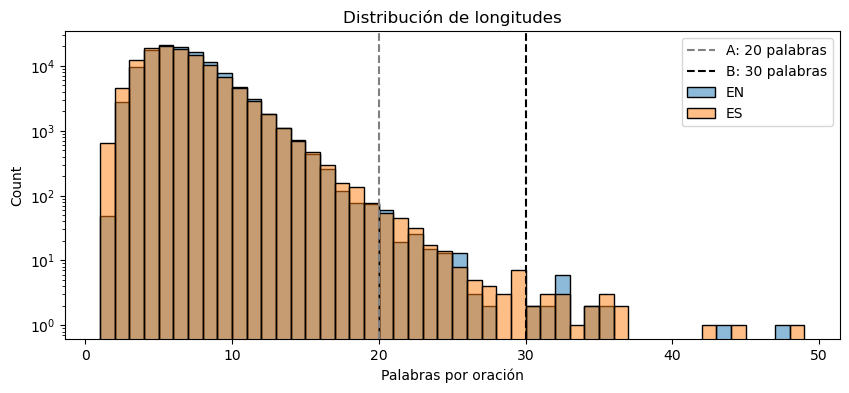

In [23]:
def n_words(s):
    return len(s.split())

en_len = np.array([n_words(en) for en, _ in pairs])
es_len = np.array([n_words(es) for _, es in pairs])

display(pd.DataFrame({'EN': en_len, 'ES': es_len}).describe(percentiles=[.5, .9, .95, .99]).T)

for max_w in [BASE_MAX_WORDS, EXT_MAX_WORDS]:
    cov = np.mean((en_len <= max_w) & (es_len <= max_w))
    print(f"Pares con <= {max_w} palabras en ambos idiomas: {cov:.2%}")

plt.figure(figsize=(10, 4))
sns.histplot(en_len, bins=range(1, 50), color='tab:blue', alpha=0.5, label='EN')
sns.histplot(es_len, bins=range(1, 50), color='tab:orange', alpha=0.5, label='ES')
plt.axvline(BASE_MAX_WORDS, color='gray', linestyle='--', label=f'A: {BASE_MAX_WORDS} palabras')
plt.axvline(EXT_MAX_WORDS, color='black', linestyle='--', label=f'B: {EXT_MAX_WORDS} palabras')
plt.yscale('log')
plt.xlabel('Palabras por oración')
plt.title('Distribución de longitudes')
plt.legend()
plt.show()

Reservamos un conjunto de test común (los últimos `N_TEST` pares con hasta `EXT_MAX_WORDS` palabras). Ningún experimento entrena con estos pares, así todos los modelos se comparan sobre las mismas oraciones.

In [24]:
pool = [(en, es) for en, es in pairs
        if n_words(en) <= EXT_MAX_WORDS and n_words(es) <= EXT_MAX_WORDS]

test_pairs = pool[-N_TEST:]
train_pool = pool[:-N_TEST]

test_en = [en for en, _ in test_pairs]
test_es = [es for _, es in test_pairs]

print(f"Pool de entrenamiento: {len(train_pool)} | Test: {len(test_pairs)}")

Pool de entrenamiento: 117946 | Test: 1000


### **Preprocesamiento**

Definimos una función que, a partir del pool, arma el subconjunto de datos, ajusta los tokenizers, aplica padding y devuelve los `tf.data.Dataset` de train y validación. Devuelve un diccionario con todo lo necesario para entrenar e inferir.

In [25]:
def prepare_data(pool, num_sentences, max_words, max_vocab=MAX_VOCAB_SIZE, val_split=VAL_SPLIT):

    subset = [(en, es) for en, es in pool
              if n_words(en) <= max_words and n_words(es) <= max_words][:num_sentences]

    input_sentences         = [en for en, _ in subset]
    output_sentences        = [es + ' <eos>' for _, es in subset]
    output_sentences_inputs = ['<sos> ' + es for _, es in subset]

    # Tokenizer de entrada (inglés)
    input_tokenizer = Tokenizer(num_words=max_vocab)
    input_tokenizer.fit_on_texts(input_sentences)
    word2idx_inputs = input_tokenizer.word_index

    # Tokenizer de salida (español). Se ajusta con las entradas y salidas del decoder
    # para que <sos> y <eos> sean de los tokens más frecuentes y nunca queden fuera del vocabulario
    output_tokenizer = Tokenizer(num_words=max_vocab, filters=OUT_FILTERS)
    output_tokenizer.fit_on_texts(output_sentences + output_sentences_inputs)
    word2idx_outputs = output_tokenizer.word_index

    enc_seq     = input_tokenizer.texts_to_sequences(input_sentences)
    dec_in_seq  = output_tokenizer.texts_to_sequences(output_sentences_inputs)
    dec_out_seq = output_tokenizer.texts_to_sequences(output_sentences)

    # Largos máximos tomados de los datos: no se trunca ninguna secuencia
    max_input_len = max(len(s) for s in enc_seq)
    max_out_len   = max(len(s) for s in dec_out_seq)

    encoder_input_sequences  = pad_sequences(enc_seq,     maxlen=max_input_len)
    decoder_input_sequences  = pad_sequences(dec_in_seq,  maxlen=max_out_len, padding='post')
    decoder_output_sequences = pad_sequences(dec_out_seq, maxlen=max_out_len, padding='post')

    split_idx = int(len(subset) * (1 - val_split))

    def make_dataset(sl, shuffle):
        ds = tf.data.Dataset.from_tensor_slices((
            (encoder_input_sequences[sl], decoder_input_sequences[sl]),
            decoder_output_sequences[sl],
        ))
        if shuffle:
            ds = ds.shuffle(len(encoder_input_sequences[sl]), seed=SEED)
        return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    data = {
        'max_words': max_words,
        'input_tokenizer': input_tokenizer,
        'output_tokenizer': output_tokenizer,
        'word2idx_inputs': word2idx_inputs,
        'word2idx_outputs': word2idx_outputs,
        'idx2word_target': {v: k for k, v in word2idx_outputs.items()},
        'nb_words_input': min(max_vocab, len(word2idx_inputs) + 1),
        'num_words_output': min(max_vocab, len(word2idx_outputs) + 1),
        'max_input_len': max_input_len,
        'max_out_len': max_out_len,
        'n_train': split_idx,
        'n_val': len(subset) - split_idx,
        'train_ds': make_dataset(slice(None, split_idx), shuffle=True),
        'val_ds': make_dataset(slice(split_idx, None), shuffle=False),
        'sample': (input_sentences[0], output_sentences[0], output_sentences_inputs[0],
                   encoder_input_sequences[0], decoder_input_sequences[0], decoder_output_sequences[0]),
    }

    print(f"Oraciones: {len(subset)} (train={data['n_train']}, val={data['n_val']})")
    print(f"Vocabulario EN: {len(word2idx_inputs)} | ES: {len(word2idx_outputs)} "
          f"(se usan {data['nb_words_input']} / {data['num_words_output']})")
    print(f"max_input_len={max_input_len}  max_out_len={max_out_len}")
    print(f"Índices <sos>={word2idx_outputs['<sos>']}  <eos>={word2idx_outputs['<eos>']}")
    return data

Generamos los datos de ambos experimentos

In [ ]:
print("=== Experimento A (réplica de clase) ===")
data_base = prepare_data(train_pool, BASE_NUM_SENTENCES, BASE_MAX_WORDS)

print("\n=== Experimento B (dataset ampliado) ===")
data_ext = prepare_data(train_pool, EXT_NUM_SENTENCES, EXT_MAX_WORDS)

=== Experimento A (réplica de clase) ===
Oraciones: 10000 (train=8500, val=1500)
Vocabulario EN: 4969 | ES: 7739 (se usan 4970 / 7740)
max_input_len=20  max_out_len=21
Índices <sos>=2  <eos>=1

=== Experimento B (dataset ampliado) ===
Oraciones: 30000 (train=25500, val=4500)
Vocabulario EN: 8066 | ES: 13834 (se usan 8000 / 8000)
max_input_len=27  max_out_len=30
Índices <sos>=2  <eos>=1


In [27]:
for line in data_ext['sample']:
    print(line)

Somebody stole my car.
Alguien robó mi auto. <eos>
<sos> Alguien robó mi auto.
[   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0  899 1089   18   98]
[   2  157 1089   23  197    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0]
[ 157 1089   23  197    1    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0]


### **Embeddings GloVe (encoder)**

Descargamos los embeddings de GloVe (mismo archivo que en clase)

In [28]:
def _is_valid_pickle(path):
    try:
        with open(path, 'rb') as f:
            head = f.read(20)
        return b'<html' not in head.lower() and b'<!doctype' not in head.lower()
    except Exception:
        return False

_PKL_PATH = 'gloveembedding.pkl'
_FILE_ID  = '1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94'

if not os.path.exists(_PKL_PATH) or not _is_valid_pickle(_PKL_PATH):
    print("Descargando gloveembedding.pkl desde Google Drive...")
    if os.path.exists(_PKL_PATH):
        os.remove(_PKL_PATH)
    try:
        import gdown
        gdown.download(id=_FILE_ID, output=_PKL_PATH, quiet=False)
    except Exception:
        os.system(f"curl -L -o {_PKL_PATH} "
                  f"'https://drive.google.com/u/0/uc?id={_FILE_ID}&export=download&confirm=t'")
    if not _is_valid_pickle(_PKL_PATH):
        raise ValueError("El archivo descargado no es un pickle válido.")
    print("Descarga completada.")
else:
    print("gloveembedding.pkl ya disponible.")

gloveembedding.pkl ya disponible.


Definimos las funciones para cargar los embeddings y armar la matriz de embeddings (iguales a las de clase)

In [29]:
def load_glove_embeddings(pkl_path):
    """Carga el pickle de GloVe y devuelve (embeddings, word2idx)."""
    max_bytes = 2**28 - 1
    raw = bytearray()
    sz  = os.path.getsize(pkl_path)
    with open(pkl_path, 'rb') as f:
        for _ in range(0, sz, max_bytes):
            raw += f.read(max_bytes)
    embeddings = pickle.loads(raw)
    idx_array  = np.arange(embeddings.shape[0])
    word2idx   = dict(zip(embeddings['word'], idx_array))
    return embeddings, word2idx


def get_word_embedding(word, embeddings, word2idx, n_features=50):
    i = word2idx.get(word, -1)
    return embeddings[i]['embedding'] if i != -1 else np.zeros(n_features)


def build_embedding_matrix(word2idx_inputs, embeddings, word2idx_glove,
                           nb_words, embed_dim=50):
    matrix = np.zeros((nb_words, embed_dim))
    for word, i in word2idx_inputs.items():
        if i < nb_words:
            vec = get_word_embedding(word, embeddings, word2idx_glove, embed_dim)
            if vec is not None and len(vec) > 0:
                matrix[i] = vec
    return matrix

In [30]:
glove_embeddings, glove_word2idx = load_glove_embeddings(_PKL_PATH)
print(f"Palabras en GloVe: {len(glove_word2idx)}")

/var/folders/xz/7wg9f3097hz464l8t67l1cdh0000gn/T/ipykernel_52910/1819461975.py:9: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  embeddings = pickle.loads(raw)


Palabras en GloVe: 1193433


### **Modelo Seq2Seq**

Definimos loss y accuracy **enmascaradas**: solo se promedian las posiciones donde el target no es padding (índice 0).

In [31]:
def masked_loss(y_true, y_pred):
    loss = keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    mask = tf.cast(tf.not_equal(y_true, 0), loss.dtype)
    return tf.reduce_sum(loss * mask) / tf.reduce_sum(mask)


def masked_accuracy(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int64)
    y_hat  = tf.argmax(y_pred, axis=-1)
    match  = tf.cast(tf.equal(y_true, y_hat), tf.float32)
    mask   = tf.cast(tf.not_equal(y_true, 0), tf.float32)
    return tf.reduce_sum(match * mask) / tf.reduce_sum(mask)

Definimos la función que construye el modelo de entrenamiento y los modelos de inferencia (encoder y decoder paso a paso). Es la misma arquitectura de clase: los modelos de inferencia reutilizan las capas (y por lo tanto los pesos) del modelo entrenado.

In [32]:
def build_seq2seq(data, n_units, embedding_matrix):

    # Encoder
    enc_inputs = Input(shape=(data['max_input_len'],), name='encoder_inputs')
    enc_emb_layer = Embedding(
        input_dim=data['nb_words_input'],
        output_dim=EMBED_DIM,
        embeddings_initializer=keras.initializers.Constant(embedding_matrix),
        trainable=False,
        mask_zero=True,
        name='encoder_embedding'
    )
    enc_emb = Dropout(DROPOUT, name='encoder_dropout')(enc_emb_layer(enc_inputs))
    enc_lstm_layer = LSTM(n_units, return_state=True, name='encoder_lstm')
    _, state_h, state_c = enc_lstm_layer(enc_emb)
    encoder_states = [state_h, state_c]

    # Decoder (teacher forcing)
    dec_inputs = Input(shape=(data['max_out_len'],), name='decoder_inputs')
    dec_emb_layer = Embedding(
        input_dim=data['num_words_output'],
        output_dim=DEC_EMBED_DIM,
        name='decoder_embedding'
    )
    dec_emb = Dropout(DROPOUT, name='decoder_dropout')(dec_emb_layer(dec_inputs))
    dec_lstm_layer = LSTM(n_units, return_sequences=True, return_state=True, name='decoder_lstm')
    dec_out, _, _ = dec_lstm_layer(dec_emb, initial_state=encoder_states)
    dec_dense_layer = Dense(data['num_words_output'], activation='softmax', name='decoder_dense')
    dec_outputs = dec_dense_layer(dec_out)

    model = Model([enc_inputs, dec_inputs], dec_outputs, name=f'seq2seq_{n_units}')

    # Inferencia: encoder que solo devuelve los estados (el Dropout no actúa en inferencia)
    encoder_model = Model(enc_inputs, encoder_states, name='encoder_inference')

    # Inferencia: decoder un token por vez
    dec_input_single = Input(shape=(1,), name='dec_input_single')
    dec_state_h_in   = Input(shape=(n_units,), name='dec_state_h')
    dec_state_c_in   = Input(shape=(n_units,), name='dec_state_c')
    dec_emb_single = dec_emb_layer(dec_input_single)
    dec_out_single, h_out, c_out = dec_lstm_layer(
        dec_emb_single, initial_state=[dec_state_h_in, dec_state_c_in]
    )
    dec_out_single = dec_dense_layer(dec_out_single)
    decoder_model = Model(
        [dec_input_single, dec_state_h_in, dec_state_c_in],
        [dec_out_single, h_out, c_out],
        name='decoder_inference'
    )

    return model, encoder_model, decoder_model

Verificamos la arquitectura con la configuración de clase

In [33]:
_m, _, _ = build_seq2seq(data_base, BASE_UNITS, np.zeros((data_base['nb_words_input'], EMBED_DIM)))
_m.summary()
del _m

Model: "seq2seq_256"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, 21)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_embedding   │ (None, 20, 50)    │    248,500 │ encoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding   │ (None, 1, 256)    │  1,981,440 │ decoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dropout     │ (None, 20, 50)    │          0 │ encoder_embeddin… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 20)        │          0 │ encoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dropout     │ (None, 21, 256)   │          0 │ decoder_embeddin… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 256),     │    314,368 │ encoder_dropout[… │
│                     │ (None, 256),      │            │ not_equal_2[0][0] │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 1, 256),  │    525,312 │ decoder_dropout[… │
│                     │ (None, 256),      │            │ encoder_lstm[0][… │
│                     │ (None, 256)]      │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dense       │ (None, 1, 7740)   │  1,989,180 │ decoder_lstm[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,058,800 (19.30 MB)

 Trainable params: 4,810,300 (18.35 MB)

 Non-trainable params: 248,500 (970.70 KB)

### **Funciones de inferencia y evaluación**

* `greedy_translate_batch`: decodificación greedy pero procesando muchas oraciones a la vez.
* `compute_bleu`: BLEU de corpus (n-gramas 1 a 4) con suavizado, tokenizando la referencia con los mismos filtros que el tokenizer de salida.

Todas las decodificaciones permiten hasta `EXT_MAX_WORDS + 1` pasos, para que el modelo A no quede limitado por su `max_out_len`.

In [34]:
MAX_DECODE_STEPS = EXT_MAX_WORDS + 1


def encode_texts(texts, data):
    seqs = data['input_tokenizer'].texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=data['max_input_len'], truncating='post')


def decode_ids(ids, data):
    eos = data['word2idx_outputs']['<eos>']
    words = []
    for i in ids:
        if i == eos:
            break
        if i > 0:
            words.append(data['idx2word_target'][i])
    return words


def greedy_translate_batch(texts, res, batch_size=256, max_steps=MAX_DECODE_STEPS):
    data = res['data']
    sos = data['word2idx_outputs']['<sos>']
    translations = []
    for start in range(0, len(texts), batch_size):
        x = encode_texts(texts[start:start + batch_size], data)
        h, c = res['encoder_model'](x, training=False)
        target = np.full((len(x), 1), sos)
        ids = np.zeros((len(x), max_steps), dtype=int)
        for t in range(max_steps):
            probs, h, c = res['decoder_model']([tf.convert_to_tensor(target), h, c], training=False)
            next_ids = np.argmax(probs.numpy()[:, 0, :], axis=-1)
            ids[:, t] = next_ids
            target = next_ids[:, None]
        translations.extend(decode_ids(row, data) for row in ids)
    return translations


def translate(text, res):
    return ' '.join(greedy_translate_batch([text], res)[0])


def tokenize_reference(text):
    return text_to_word_sequence(text, filters=OUT_FILTERS)


def compute_bleu(predictions, reference_texts):
    references = [[tokenize_reference(t)] for t in reference_texts]
    return corpus_bleu(references, predictions, smoothing_function=SmoothingFunction().method1)

Definimos la función que entrena y evalúa un experimento. Usamos los mismos callbacks de clase (`ReduceLROnPlateau` + `EarlyStopping` con `restore_best_weights`). Como la loss está enmascarada y promediada por token, la perplejidad se obtiene como `exp(val_loss)`.

In [35]:
results = {}  # guardamos modelo, historial y métricas de cada corrida


def run_experiment(name, data, n_units):
    print("_" * 60)
    print(f"Experimento {name}: n_units={n_units}, oraciones train={data['n_train']}, "
          f"max_words={data['max_words']}")

    keras.utils.set_random_seed(SEED)

    embedding_matrix = build_embedding_matrix(
        data['word2idx_inputs'], glove_embeddings, glove_word2idx,
        data['nb_words_input'], EMBED_DIM
    )
    print(f"Embeddings nulos: {np.sum(np.sum(embedding_matrix**2, axis=1) == 0)}")

    model, encoder_model, decoder_model = build_seq2seq(data, n_units, embedding_matrix)
    model.compile(
        loss=masked_loss,
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        metrics=[masked_accuracy]
    )

    callbacks = [
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
        EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1),
    ]

    t0 = time.time()
    hist = model.fit(
        data['train_ds'],
        validation_data=data['val_ds'],
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=2
    )
    train_time = time.time() - t0

    best = int(np.argmin(hist.history['val_loss']))
    res = {
        'name': name,
        'n_units': n_units,
        'n_train': data['n_train'],
        'max_words': data['max_words'],
        'params': model.count_params(),
        'epochs': len(hist.history['val_loss']),
        'best_epoch': best + 1,
        'train_loss': hist.history['loss'][best],
        'val_loss': hist.history['val_loss'][best],
        'train_acc': hist.history['masked_accuracy'][best],
        'val_acc': hist.history['val_masked_accuracy'][best],
        'val_ppl': float(np.exp(hist.history['val_loss'][best])),
        'train_min': train_time / 60,
        'history': hist.history,
        'model': model,
        'encoder_model': encoder_model,
        'decoder_model': decoder_model,
        'data': data,
    }

    # BLEU sobre el test común
    res['test_preds'] = greedy_translate_batch(test_en, res)
    res['test_bleu'] = compute_bleu(res['test_preds'], test_es)

    results[name] = res
    print(f"-> val_loss={res['val_loss']:.4f}  val_acc={res['val_acc']:.4f}  "
          f"val_ppl={res['val_ppl']:.2f}  test_BLEU={res['test_bleu']:.4f}  "
          f"tiempo={res['train_min']:.1f} min")
    return res

### **Entrenamiento**

**Experimento A**: réplica de la configuración de clase (10k oraciones, secuencias cortas, 256 unidades)

In [36]:
run_experiment(f'A_base_{BASE_UNITS}', data_base, BASE_UNITS);

____________________________________________________________
Experimento A_base_256: n_units=256, oraciones train=8500, max_words=20
Embeddings nulos: 211
Epoch 1/30


/Users/luis/miniconda3/envs/ciencia_de_datos/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


133/133 - 17s - 127ms/step - loss: 6.5550 - masked_accuracy: 0.1463 - val_loss: 6.0283 - val_masked_accuracy: 0.1598 - learning_rate: 5.0000e-04
Epoch 2/30
133/133 - 16s - 123ms/step - loss: 5.7835 - masked_accuracy: 0.1706 - val_loss: 5.8373 - val_masked_accuracy: 0.1774 - learning_rate: 5.0000e-04
Epoch 3/30
133/133 - 15s - 112ms/step - loss: 5.5558 - masked_accuracy: 0.1885 - val_loss: 5.6953 - val_masked_accuracy: 0.1992 - learning_rate: 5.0000e-04
Epoch 4/30
133/133 - 16s - 122ms/step - loss: 5.3458 - masked_accuracy: 0.2053 - val_loss: 5.5679 - val_masked_accuracy: 0.2054 - learning_rate: 5.0000e-04
Epoch 5/30
133/133 - 16s - 118ms/step - loss: 5.1697 - masked_accuracy: 0.2150 - val_loss: 5.4686 - val_masked_accuracy: 0.2172 - learning_rate: 5.0000e-04
Epoch 6/30
133/133 - 16s - 119ms/step - loss: 5.0063 - masked_accuracy: 0.2310 - val_loss: 5.3537 - val_masked_accuracy: 0.2302 - learning_rate: 5.0000e-04
Epoch 7/30
133/133 - 18s - 132ms/step - loss: 4.8443 - masked_accuracy: 0.2

**Experimento B**: dataset ampliado y secuencias más largas, variando el número de unidades de las LSTM

In [37]:
for units in UNITS_LIST:
    run_experiment(f'B_ext_{units}', data_ext, units)

____________________________________________________________
Experimento B_ext_64: n_units=64, oraciones train=25500, max_words=30
Embeddings nulos: 398
Epoch 1/30
399/399 - 34s - 85ms/step - loss: 6.3867 - masked_accuracy: 0.1307 - val_loss: 5.8071 - val_masked_accuracy: 0.1465 - learning_rate: 5.0000e-04
Epoch 2/30
399/399 - 32s - 79ms/step - loss: 5.6983 - masked_accuracy: 0.1534 - val_loss: 5.5996 - val_masked_accuracy: 0.1662 - learning_rate: 5.0000e-04
Epoch 3/30
399/399 - 32s - 80ms/step - loss: 5.4933 - masked_accuracy: 0.1781 - val_loss: 5.4116 - val_masked_accuracy: 0.1891 - learning_rate: 5.0000e-04
Epoch 4/30
399/399 - 32s - 81ms/step - loss: 5.2980 - masked_accuracy: 0.1971 - val_loss: 5.2359 - val_masked_accuracy: 0.2100 - learning_rate: 5.0000e-04
Epoch 5/30
399/399 - 32s - 79ms/step - loss: 5.1089 - masked_accuracy: 0.2190 - val_loss: 5.0688 - val_masked_accuracy: 0.2293 - learning_rate: 5.0000e-04
Epoch 6/30
399/399 - 33s - 84ms/step - loss: 4.9362 - masked_accuracy: 0

### **Resultados**

Tabla comparativa de todas las configuraciones

In [38]:
_hidden = ['history', 'model', 'encoder_model', 'decoder_model', 'data', 'test_preds']
summary = pd.DataFrame([{k: v for k, v in r.items() if k not in _hidden}
                        for r in results.values()]).set_index('name')
summary.round(4)

,n_units,n_train,max_words,params,epochs,best_epoch,train_loss,val_loss,train_acc,val_acc,val_ppl,train_min,test_bleu
name,,,,,,,,,,,,,
A_base_256,256,8500,20,5058800,30,28,2.6890,4.5832,0.4400,0.3406,97.8293,8.9974,0.0340
B_ext_64,64,25500,30,3079616,30,30,3.2205,3.8217,0.3892,0.3505,45.6799,16.1839,0.0295
B_ext_128,128,25500,30,3768768,30,30,2.5680,3.4408,0.4586,0.4013,31.2114,24.2930,0.0580
B_ext_256,256,25500,30,5343680,30,29,1.7822,3.1415,0.5891,0.4515,23.1393,46.5456,0.0876
B_ext_512,512,25500,30,9279936,26,22,1.3499,3.0946,0.6824,0.4662,22.0779,79.0303,0.1107


#### Análisis: resumen de resultados

| Modelo | Oraciones train | Máx. palabras | `n_units` | Parámetros | Epochs (mejor) | `val_loss` | Perplejidad val | Accuracy val (enmasc.) | BLEU test | Tiempo (min) |
|---|---|---|---|---|---|---|---|---|---|---|
| A_base_256 | 8.500 | 20 | 256 | 5.06 M | 30 (28) | 4.583 | 97.8 | 0.341 | 0.034 | 9.0 |
| B_ext_64 | 25.500 | 30 | 64 | 3.08 M | 30 (30) | 3.822 | 45.7 | 0.351 | 0.030 | 16.2 |
| B_ext_128 | 25.500 | 30 | 128 | 3.77 M | 30 (30) | 3.441 | 31.2 | 0.401 | 0.058 | 24.3 |
| B_ext_256 | 25.500 | 30 | 256 | 5.34 M | 30 (29) | 3.142 | 23.1 | 0.452 | 0.088 | 46.5 |
| **B_ext_512** | 25.500 | 30 | 512 | 9.28 M | 26 (22) | **3.095** | **22.1** | **0.466** | **0.111** | 79.0 |

El BLEU está en escala 0-1 (0.111 ≈ 11 sobre 100) y se calcula sobre el **mismo test de 1000 oraciones** para todos los modelos. La accuracy es **enmascarada** (no cuenta el padding), por eso es más baja que la reportada en clase.

#### Réplica de clase vs. dataset ampliado (A_base_256 vs. B_ext_256)

* Con la misma arquitectura (256 unidades), triplicar los datos fue el cambio con mayor impacto. La perplejidad de validación bajó de 97.8 a 23.1 (−76 %), el BLEU en test pasó de 0.034 a 0.088 (×2.6) y la accuracy enmascarada de 0.34 a 0.45.
* Con 8.500 oraciones el modelo A memoriza: su brecha `val_loss − train_loss` es 1.89, contra 1.36 del B_ext_256, aun cuando este último llegó a una loss de entrenamiento mucho menor. Con ~7.700 palabras en español, la mayoría aparece muy pocas veces en 8.500 oraciones.
* Sobre las secuencias más largas: el dataset casi no tiene oraciones largas. El percentil 99 es de 14 palabras (EN) y 15 (ES); el filtro de 20 palabras ya conserva el 99.85 % de los pares y el de 30 el 99.98 %. Ampliar el límite subió `max_input_len` de 20 a 27 y `max_out_len` de 21 a 30, pero aportó muy pocos ejemplos nuevos: la mejora viene de la cantidad de datos, no de la longitud. Por la misma razón el test tiene solo 7 oraciones de más de 15 palabras, y el BLEU de esos tramos no es representativo.

Graficamos la loss y la accuracy enmascarada de cada corrida

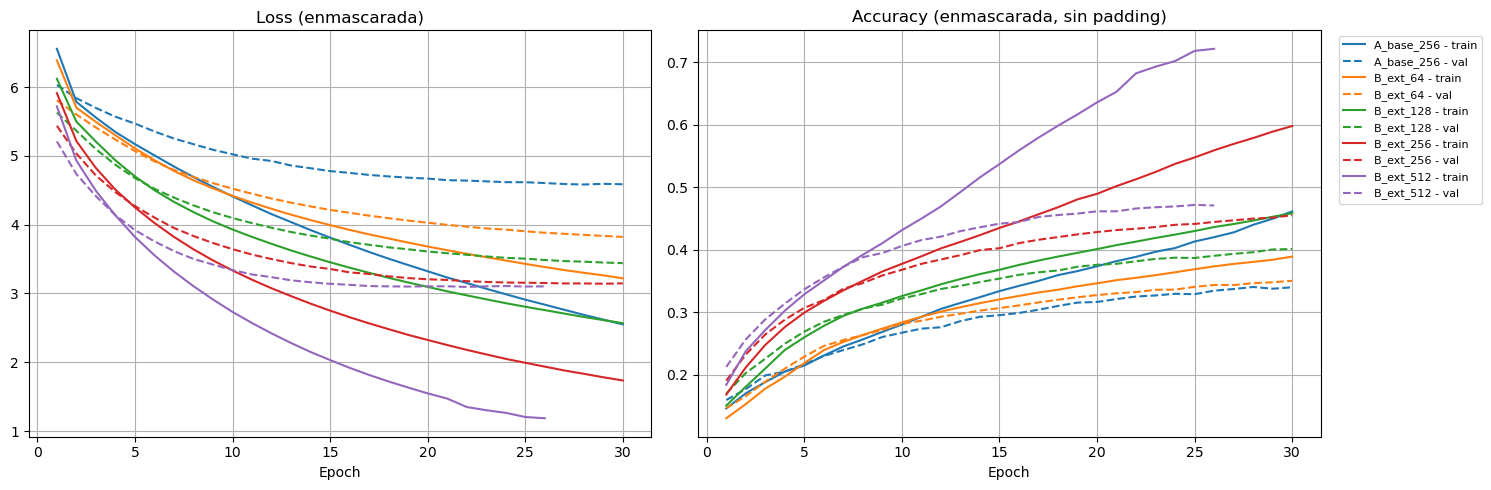

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
palette = sns.color_palette('tab10', len(results))

for color, (name, r) in zip(palette, results.items()):
    h = r['history']
    ep = range(1, len(h['loss']) + 1)
    axes[0].plot(ep, h['loss'], color=color, label=f'{name} - train')
    axes[0].plot(ep, h['val_loss'], color=color, linestyle='--', label=f'{name} - val')
    axes[1].plot(ep, h['masked_accuracy'], color=color, label=f'{name} - train')
    axes[1].plot(ep, h['val_masked_accuracy'], color=color, linestyle='--', label=f'{name} - val')

axes[0].set_title('Loss (enmascarada)')
axes[1].set_title('Accuracy (enmascarada, sin padding)')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.grid(True)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

Impacto del número de neuronas recurrentes (experimento B)

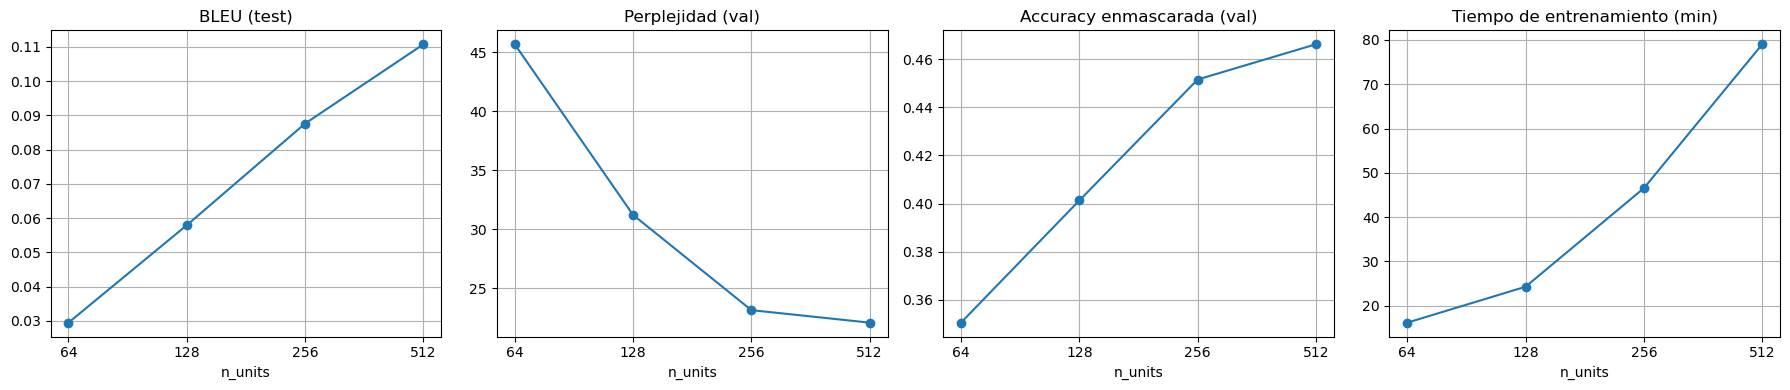

,params,train_loss,val_loss,train_acc,val_acc,gap_loss
name,,,,,,
B_ext_64,3079616,3.2205,3.8217,0.3892,0.3505,0.6012
B_ext_128,3768768,2.5680,3.4408,0.4586,0.4013,0.8728
B_ext_256,5343680,1.7822,3.1415,0.5891,0.4515,1.3594
B_ext_512,9279936,1.3499,3.0946,0.6824,0.4662,1.7446


In [40]:
ext = summary[summary.index.str.startswith('B_')].sort_values('n_units')

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
metrics = [('test_bleu', 'BLEU (test)'), ('val_ppl', 'Perplejidad (val)'),
           ('val_acc', 'Accuracy enmascarada (val)'), ('train_min', 'Tiempo de entrenamiento (min)')]
for ax, (col, title) in zip(axes, metrics):
    ax.plot(ext['n_units'], ext[col], marker='o')
    ax.set_xscale('log', base=2)
    ax.set_xticks(ext['n_units'])
    ax.set_xticklabels(ext['n_units'])
    ax.set_xlabel('n_units')
    ax.set_title(title)
    ax.grid(True)
plt.tight_layout()
plt.show()

# Brecha de generalización: cuánto mejor es train que val en la mejor epoch
display(ext[['params', 'train_loss', 'val_loss', 'train_acc', 'val_acc']]
        .assign(gap_loss=ext['val_loss'] - ext['train_loss']).round(4))

#### Análisis: impacto del número de neuronas recurrentes

* **Mejora monótona** con `n_units`: BLEU 0.030 → 0.058 → 0.088 → 0.111 y perplejidad 45.7 → 31.2 → 23.1 → 22.1.
* **Rendimientos decrecientes** en perplejidad: −32 % (64→128), −26 % (128→256) y solo −5 % (256→512). El BLEU sigue subiendo (+26 % de 256 a 512): el modelo grande no mejora mucho la distribución completa, pero acierta más seguido la palabra más probable, que es la que usa la decodificación greedy.
* **Costo**: de 64 a 512 los parámetros se triplican (3.1 M → 9.3 M) y el tiempo de entrenamiento crece ×4.9 (16 → 79 min en CPU). Pasar de 256 a 512 cuesta +74 % de parámetros y +70 % de tiempo para un 5 % menos de perplejidad.
* **Dónde están los parámetros**: los embeddings son fijos (2.45 M: 400 k de GloVe congelados + 2.05 M del decoder). Las dos LSTM crecen cuadráticamente (0.11 M con 64 unidades → 2.73 M con 512) y la `Dense` de salida linealmente (0.52 M → 4.10 M). Con 64 unidades dominan los embeddings; con 512, la capa de salida y las LSTM.
* **Sobreajuste**: la brecha `val_loss − train_loss` crece con el tamaño (0.60 → 0.87 → 1.36 → 1.74) y la accuracy de train se separa de la de validación (0.68 vs. 0.47 con 512). B_ext_512 es el único donde actuó el *early stopping* (mejor epoch 22, cortó en la 26).
* **Los modelos de 64, 128 y 256 no convergieron**: su mejor epoch fue la 29-30, con la `val_loss` todavía bajando. Sus resultados son una cota inferior y la comparación mezcla capacidad con velocidad de convergencia: con más epochs la diferencia con 512 probablemente se achicaría.
* B_ext_64 subajusta (loss de train 3.22): tiene mejor perplejidad que A_base_256 (45.7 vs. 97.8) gracias a los datos, pero peor BLEU (0.030 vs. 0.034). Con tan poca capacidad aprende la distribución general del español pero no alcanza para producir n-gramas exactos.

BLEU según la longitud de la oración de entrada. Permite ver cómo se degrada la traducción con oraciones largas (el encoder comprime toda la oración en un único vector de estado). La columna `n` indica cuántas oraciones hay en cada tramo: los tramos 16-20 (6 oraciones) y 21-30 (1 oración) son demasiado chicos para sacar conclusiones.

,A_base_256,B_ext_128,B_ext_256,B_ext_512,B_ext_64,n
longitud,,,,,,
1-5,0.0275,0.0574,0.0944,0.1171,0.0140,439
6-10,0.0374,0.0568,0.0928,0.1163,0.0349,485
11-15,0.0201,0.0598,0.0629,0.0888,0.0093,69
16-20,0.0413,0.0446,0.0424,0.0414,0.0400,6
21-30,0.0266,0.0208,0.0208,0.0210,0.0212,1


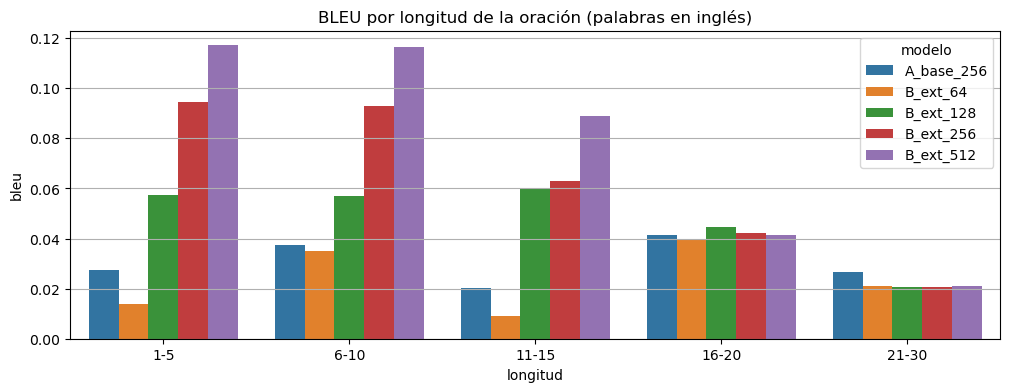

In [41]:
test_len = np.array([n_words(en) for en in test_en])
bins = [0, 5, 10, 15, 20, EXT_MAX_WORDS]

rows = []
for name, r in results.items():
    for lo, hi in zip(bins[:-1], bins[1:]):
        idx = np.where((test_len > lo) & (test_len <= hi))[0]
        if len(idx) == 0:
            continue
        rows.append({
            'modelo': name,
            'longitud': f'{lo + 1}-{hi}',
            'n': len(idx),
            'bleu': compute_bleu([r['test_preds'][i] for i in idx], [test_es[i] for i in idx]),
        })
bleu_by_len = pd.DataFrame(rows)
bucket_order = [f'{lo + 1}-{hi}' for lo, hi in zip(bins[:-1], bins[1:])]
bleu_by_len['longitud'] = pd.Categorical(bleu_by_len['longitud'], categories=bucket_order, ordered=True)

display(bleu_by_len.pivot_table(index='longitud', columns='modelo', values='bleu', observed=True).round(4)
        .join(bleu_by_len.groupby('longitud', observed=True)['n'].first()))

plt.figure(figsize=(12, 4))
sns.barplot(data=bleu_by_len, x='longitud', y='bleu', hue='modelo')
plt.title('BLEU por longitud de la oración (palabras en inglés)')
plt.grid(True, axis='y')
plt.show()

#### Análisis: calidad según la longitud

**Según la longitud (BLEU del mejor modelo, B_ext_512): 0.117 con 1-5 palabras, 0.116 con 6-10 y 0.089 con 11-15 (−24 %). En B_ext_256 la caída es mayor (0.093 → 0.063, −32 %). Esto es consistente con el cuello de botella del vector de contexto.

### **Ejemplos de traducción**

Tomamos el mejor modelo según BLEU en test

In [42]:
best_name = summary['test_bleu'].idxmax()
best = results[best_name]
print(f"Mejor modelo: {best_name}  (BLEU={best['test_bleu']:.4f})")

Mejor modelo: B_ext_512  (BLEU=0.1107)


Ejemplos del conjunto de test (oraciones nunca vistas en entrenamiento)

In [43]:
rng = np.random.default_rng(SEED)
example_idx = rng.choice(len(test_en), size=8, replace=False)

for i in example_idx:
    print(f"EN:        {test_en[i]}")
    print(f"ES (real): {test_es[i]}")
    print(f"ES (pred): {' '.join(best['test_preds'][i])}\n")

EN:        Can you give an exact report of what happened?
ES (real): ¿Puede usted describir exactamente lo que pasó?
ES (pred): puedes darme un libro en el periódico que lo has pasado

EN:        I've lost my ticket.
ES (real): He perdido mi boleto.
ES (pred): perdí mi dignidad

EN:        I don't know what to do anymore.
ES (real): Ya no sé qué hacer.
ES (pred): no sé qué hacer

EN:        I was just remembering.
ES (real): Solo estaba recordando.
ES (pred): estaba realmente siguiendo

EN:        I lost another chance.
ES (real): Perdí otra oportunidad.
ES (pred): yo lo he perdido

EN:        Tom isn't joking.
ES (real): Tom no está jodiendo.
ES (pred): tom no está bromeando

EN:        I want to spend my life with Mary.
ES (real): Quiero pasar mi vida con Mary.
ES (pred): quiero pasar con mi amigo con mary

EN:        Can you climb the tree?
ES (real): ¿Puedes trepar al árbol?
ES (pred): puedes arrojar en el suelo



Las mismas oraciones traducidas por cada configuración, para comparar cualitativamente

In [44]:
compare = pd.DataFrame(
    {'EN': [test_en[i] for i in example_idx], 'ES (real)': [test_es[i] for i in example_idx]}
)
for name, r in results.items():
    compare[name] = [' '.join(r['test_preds'][i]) for i in example_idx]

with pd.option_context('display.max_colwidth', None):
    display(compare)

,EN,ES (real),A_base_256,B_ext_64,B_ext_128,B_ext_256,B_ext_512
0,Can you give an exact report of what happened?,¿Puede usted describir exactamente lo que pasó?,puedes hablar en el problema de la escuela,te gustaría saber la vida en el,puedes hacer el tiempo que no lo haga,puedes hacer una respuesta a este error,puedes darme un libro en el periódico que lo has pasado
1,I've lost my ticket.,He perdido mi boleto.,estoy en mi casa,estoy en mi coche,he visto mi coche,perdí mi número de regreso,perdí mi dignidad
2,I don't know what to do anymore.,Ya no sé qué hacer.,no sé que hacer eso,no quiero que no me,no sé que no lo haga,no sé qué hacer,no sé qué hacer
3,I was just remembering.,Solo estaba recordando.,me he visto ayer,me gusta la escuela,estaba de acuerdo con él,estaba solo,estaba realmente siguiendo
4,I lost another chance.,Perdí otra oportunidad.,yo me he visto,tengo un coche,yo he visto un minuto,yo aprobé el plan,yo lo he perdido
5,Tom isn't joking.,Tom no está jodiendo.,tom no está enojado,tom no es,tom no está,tom no está diciendo,tom no está bromeando
6,I want to spend my life with Mary.,Quiero pasar mi vida con Mary.,quiero que quiero tu trabajo de tom,quiero que me vayas a mi casa,quiero que a mi perro,quiero quedarme con mi vida con tom,quiero pasar con mi amigo con mary
7,Can you climb the tree?,¿Puedes trepar al árbol?,puedes abrir la puerta,puedes pasarme la mesa,puedes cerrar la mesa,puedes arrojar en el árbol,puedes arrojar en el suelo


Frases nuevas (las de clase y algunas más largas)

In [45]:
new_sentences = [
    "My mother says hi.",
    "Where is the train station?",
    "I love learning languages.",
    "Can you help me?",
    "I don't know what I would have done without your help.",
    "Tom told me that he wanted to buy a new car next year.",
    "If it rains tomorrow, we will stay at home and watch a movie.",
]

for s in new_sentences:
    print(f"EN: {s}")
    for name, r in results.items():
        print(f"   {name:<12} {translate(s, r)}")
    print()

EN: My mother says hi.
   A_base_256   mi madre me dijo
   B_ext_64     mi padre me dijo que él
   B_ext_128    mi madre le dijo a mary
   B_ext_256    mi padre sabe a tom
   B_ext_512    mi padre le dijo hola

EN: Where is the train station?
   A_base_256   dónde está en el tren
   B_ext_64     dónde está en la casa
   B_ext_128    dónde está el parque
   B_ext_256    dónde está el tren
   B_ext_512    dónde está el tren de tren

EN: I love learning languages.
   A_base_256   sé la verdad
   B_ext_64     me gusta la vida
   B_ext_128    me gusta el francés
   B_ext_256    me encantan los lenguas
   B_ext_512    me encantan los lenguas extranjeras

EN: Can you help me?
   A_base_256   puedes ir
   B_ext_64     te puedes hacer
   B_ext_128    puedes ayudarme
   B_ext_256    puedes ayudarme
   B_ext_512    puedes ayudarme

EN: I don't know what I would have done without your help.
   A_base_256   no sé que no me gusta nada de ti
   B_ext_64     no quiero que no me gusta nada de ti
   B_e

#### Análisis: calidad de las traducciones

* **Aciertos**: *"Can you help me?"* → "puedes ayudarme" (128, 256 y 512); *"I don't know what to do anymore."* → "no sé qué hacer" (pierde el "ya"); *"Tom isn't joking."* → "tom no está bromeando". Esta última es una traducción correcta, pero la referencia es "Tom no está jodiendo" y **BLEU la penaliza**: con una sola referencia por oración, la métrica subestima la calidad real.
* **Estructura correcta, contenido equivocado**: *"I've lost my ticket."* → "perdí mi dignidad"; *"Can you climb the tree?"* → "puedes arrojar en el suelo"; *"I lost another chance."* → "yo lo he perdido". El modelo aprende bien las plantillas sintácticas y los verbos frecuentes, pero reemplaza los sustantivos poco frecuentes (boleto, árbol, oportunidad).
* **Sesgo hacia tokens frecuentes**: "tom", "mary", "casa", "escuela" y "coche" aparecen como relleno, sobre todo en los modelos chicos (B_ext_64: "estoy en mi coche", "me gusta la escuela").
* **Confusión entre palabras relacionadas**: *"My mother says hi."* → "mi padre le dijo hola" (madre/padre aparecen en contextos casi idénticos).
* **Errores de concordancia y repeticiones**: "me encantan los lenguas extranjeras", "el tren de tren", "un nuevo nuevo nuevo" (128).
* **Oraciones largas**: para *"If it rains tomorrow, we will stay at home and watch a movie."* todos los modelos generan frases fluidas pero sin relación con la entrada ("si vas a estar en casa a las siete y media hora"): conservan el comienzo ("si") y luego "alucinan". En *"Tom told me that he wanted to buy a new car next year."* el de 256 recupera parte del significado ("tom me dijo que no quería comprar un trabajo nuevo").
* **La mejora entre configuraciones se ve cualitativamente**. Para *"I want to spend my life with Mary."*: A_base_256 → "quiero que quiero tu trabajo de tom", B_ext_256 → "quiero quedarme con mi vida con tom", B_ext_512 → "quiero pasar con mi amigo con mary".

### **(Actividades Opcionales) Estrategias de generación**

Comparamos con el mejor modelo:

* **Greedy**: en cada paso se elige la palabra más probable.
* **Beam search**: se mantienen las `beam_width` hipótesis parciales más probables. El puntaje final se normaliza por longitud (`length_penalty`) para no favorecer traducciones cortas.
* **Muestreo con temperatura**: se muestrea la siguiente palabra de la distribución `p^(1/T)`. Con `T < 1` es más conservador; con `T > 1` es más diverso.

In [48]:
def beam_search_translate(text, res, beam_width=3, length_penalty=0.7, max_steps=MAX_DECODE_STEPS):
    data = res['data']
    sos = data['word2idx_outputs']['<sos>']
    eos = data['word2idx_outputs']['<eos>']

    h, c = res['encoder_model'](encode_texts([text], data), training=False)
    beams = [([sos], 0.0, h.numpy(), c.numpy())]   # (tokens, log-prob, h, c)
    completed = []

    for _ in range(max_steps):
        target = np.array([[b[0][-1]] for b in beams])
        H = np.concatenate([b[2] for b in beams])
        C = np.concatenate([b[3] for b in beams])
        probs, H_new, C_new = res['decoder_model'](
            [tf.convert_to_tensor(target), tf.convert_to_tensor(H), tf.convert_to_tensor(C)], training=False
        )
        log_probs = np.log(probs.numpy()[:, 0, :] + 1e-12)
        log_probs[:, 0] = -np.inf                       # nunca generar padding
        H_new, C_new = H_new.numpy(), C_new.numpy()

        candidates = []
        for b, (tokens, score, _, _) in enumerate(beams):
            for idx in np.argsort(log_probs[b])[-beam_width:]:
                candidates.append((tokens + [int(idx)], score + log_probs[b, idx],
                                   H_new[b:b + 1], C_new[b:b + 1]))
        candidates.sort(key=lambda x: x[1], reverse=True)

        beams = []
        for cand in candidates:
            if cand[0][-1] == eos:
                completed.append(cand)
            else:
                beams.append(cand)
            if len(beams) == beam_width:
                break
        if not beams or len(completed) >= beam_width:
            break

    completed = completed or beams
    best_cand = max(completed, key=lambda x: x[1] / (len(x[0]) - 1) ** length_penalty)
    return decode_ids(best_cand[0][1:], data)


def sample_translate(text, res, temperature=1.0, max_steps=MAX_DECODE_STEPS):
    data = res['data']
    sos = data['word2idx_outputs']['<sos>']
    eos = data['word2idx_outputs']['<eos>']

    h, c = res['encoder_model'](encode_texts([text], data), training=False)
    target = np.array([[sos]])
    ids = []
    for _ in range(max_steps):
        probs, h, c = res['decoder_model']([tf.convert_to_tensor(target), h, c], training=False)
        p = probs.numpy()[0, 0].astype('float64')
        p[0] = 0.0                                      # nunca generar padding
        logits = np.log(p + 1e-12) / temperature
        p = np.exp(logits - logits.max())
        p /= p.sum()
        idx = int(np.random.choice(len(p), p=p))
        ids.append(idx)
        if idx == eos:
            break
        target[0, 0] = idx
    return decode_ids(ids, data)

BLEU de cada estrategia sobre un subconjunto del test (beam search y sampling decodifican oración por oración, por eso usamos menos oraciones)

In [49]:
N_STRAT = 200
np.random.seed(SEED)
sub_en, sub_es = test_en[:N_STRAT], test_es[:N_STRAT]

strategies = {
    'greedy':        lambda s: greedy_translate_batch([s], best)[0],
    'beam (k=3)':    lambda s: beam_search_translate(s, best, beam_width=3),
    'beam (k=5)':    lambda s: beam_search_translate(s, best, beam_width=5),
    'sampling T=0.5': lambda s: sample_translate(s, best, temperature=0.5),
    'sampling T=1.0': lambda s: sample_translate(s, best, temperature=1.0),
}

strategy_preds = {}
rows = []
for name, fn in strategies.items():
    t0 = time.time()
    preds = [fn(s) for s in sub_en]
    strategy_preds[name] = preds
    rows.append({'estrategia': name, 'bleu': compute_bleu(preds, sub_es),
                 'seg': time.time() - t0})

pd.DataFrame(rows).set_index('estrategia').round(4)

,bleu,seg
estrategia,,
greedy,0.1182,47.6258
beam (k=3),0.1139,23.0654
beam (k=5),0.1237,22.9716
sampling T=0.5,0.0870,19.0648
sampling T=1.0,0.0364,19.1135


In [50]:
for i in range(5):
    print(f"EN:   {sub_en[i]}")
    print(f"REAL: {sub_es[i]}")
    for name, preds in strategy_preds.items():
        print(f"   {name:<15} {' '.join(preds[i])}")
    print()

EN:   This question is not easy.
REAL: Esta pregunta no es fácil.
   greedy          esta frase no es fácil
   beam (k=3)      este libro no es fácil
   beam (k=5)      este libro no es fácil
   sampling T=0.5  esta pregunta es fácil de entender
   sampling T=1.0  esta frase no es fácil

EN:   They're still alive.
REAL: Todavía están vivos.
   greedy          todavía no está vivo
   beam (k=3)      sigo vivo
   beam (k=5)      sigo vivo
   sampling T=0.5  todavía estoy totalmente perdida
   sampling T=1.0  todavía estamos uno de morir

EN:   You have nothing to lose.
REAL: No tienes nada que perder.
   greedy          no tienes nada que perder
   beam (k=3)      no tienes nada que perder
   beam (k=5)      no tienes nada que perder
   sampling T=0.5  no tienes que nada
   sampling T=1.0  estarías dispuesto por tener verdad

EN:   I'm a married man.
REAL: Soy un hombre casado.
   greedy          es una mujer más
   beam (k=3)      él es un hombre solitario
   beam (k=5)      él es un ho

#### Análisis: estrategias de generación

Con el mejor modelo (B_ext_512), sobre las primeras 200 oraciones del test:

| Estrategia | BLEU | Tiempo (s) |
|---|---|---|
| greedy | 0.118 | 47.6 |
| beam search (k=3) | 0.114 | 23.1 |
| **beam search (k=5)** | **0.124** | 23.0 |
| sampling T=0.5 | 0.087 | 19.1 |
| sampling T=1.0 | 0.036 | 19.1 |

* **Beam search mejora poco**: k=5 sube el BLEU un 4.7 % respecto de greedy, y k=3 incluso lo baja un 3.6 %. Con 200 oraciones, diferencias de este tamaño están dentro del ruido (unas pocas oraciones mueven el BLEU). Los errores del modelo están en las probabilidades mismas (el sustantivo incorrecto ya tiene probabilidad alta), no en la búsqueda; una búsqueda más exhaustiva no los corrige.
* El greedy da 0.118 en este subconjunto contra 0.111 en el test completo: estas 200 oraciones son algo más fáciles, así que conviene comparar las estrategias solo entre sí.
* **Cualitativamente**, beam search completa frases que greedy deja truncadas (*"Tom started whimpering."*: greedy "tom empezó a" → beam "tom empezó a cantar") y da estructuras más coherentes (*"I'm a married man."*: greedy "es una mujer más" → beam "él es un hombre solitario", con el sustantivo correcto pero la persona y el adjetivo equivocados). También tiende a opciones genéricas y más cortas: *"This question is not easy."* pasa de "esta frase no es fácil" a "este libro no es fácil", y *"They're still alive."* de "todavía no está vivo" a "sigo vivo". Es el sesgo conocido de beam search hacia secuencias frecuentes y cortas, aun con `length_penalty=0.7`.
* **El muestreo empeora el BLEU**: −26 % con T=0.5 y −69 % con T=1.0. A veces acierta palabras que greedy no encuentra ("esta pregunta", "comenzó"), pero pierde información clave (*"This question is not easy."* → "esta pregunta es fácil de entender", sin la negación) y con T=1.0 produce frases incoherentes ("estarías dispuesto por tener verdad"). La diversidad sirve para generar texto libre, no para traducir, donde se busca la salida más probable.

### **Limitaciones y conclusión**

#### Limitaciones del enfoque

* **Cuello de botella del vector de contexto**: toda la oración se comprime en `(h, c)`; de ahí la caída con la longitud y las "alucinaciones" en oraciones largas. Un mecanismo de **atención** (Bahdanau/Luong) o un Transformer resuelven esto.
* **Vocabulario cerrado**: en el experimento B el español tiene 13.834 palabras y solo se usan 8.000. Las restantes se descartan silenciosamente de los targets, y conjugaciones y sustantivos poco frecuentes no se pueden generar. La tokenización por subpalabras (BPE/SentencePiece) lo mitiga.
* **Exposure bias**: en entrenamiento el decoder recibe la palabra correcta anterior (*teacher forcing*), pero en inferencia recibe su propia predicción, así que un error temprano se propaga (ver las repeticiones).
* **Embeddings**: GloVe solo en el encoder y congelado; el decoder aprende sus embeddings desde cero con 25.500 oraciones.
* **Entrenamiento limitado por cómputo**: 30 epochs en CPU (casi 3 h en total) no alcanzaron para que converjan los modelos de 64-256 unidades.
* **Métrica**: BLEU con una única referencia penaliza sinónimos y paráfrasis válidas ("bromeando" vs. "jodiendo", "auto" vs. "coche").
* **Datos**: frases cortas y coloquiales de Anki. El modelo no generaliza a textos largos ni a otros dominios.

#### Conclusión

El factor más importante fue la cantidad de datos. Con la misma arquitectura, triplicarlos multiplicó el BLEU por 2.6. El número de neuronas también mejora todas las métricas, con rendimientos decrecientes en perplejidad a partir de 256 unidades y un costo de cómputo y un sobreajuste crecientes; 512 unidades dio el mejor resultado (BLEU 0.111, perplejidad 22.1). 

Aun así, la calidad absoluta es baja: el modelo traduce bien frases cortas y frecuentes, mantiene la estructura gramatical en general, pero sustituye palabras de contenido y falla en oraciones largas. 

En cuanto a la decodificación, beam search (k=5) dio una mejora marginal (BLEU 0.124 vs. 0.118 de greedy sobre 200 oraciones) y el muestreo empeoró los resultados: el límite está en el modelo, no en la estrategia de búsqueda. 

Los próximos pasos con mayor impacto serían agregar atención, entrenar más epochs (o en GPU) con el dataset completo (~118k pares) y usar subpalabras para el vocabulario.